# Data exploration: PAWS-Wiki

## 1. Dataset Overview

This project uses **PAWS-Wiki (Paraphrase Adversaries from Word Scrambling)**, a dataset designed for binary paraphrase detection. Each instance consists of two sentences labelled according to whether they convey the same meaning.

Unlike conventional paraphrase datasets, PAWS-Wiki contains sentence pairs with high lexical overlap but potentially different meanings. This makes it particularly challenging for models that rely primarily on word occurrence and frequency.

The dataset was selected to investigate the limitations of lexical representations and assess whether incorporating word-order information improves paraphrase detection.

### 1.1. Imports and Setup

The following libraries are used for dataset loading, exploratory data analysis, text tokenisation, and visualisation.

In [36]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from IPython.display import display

## 2. Dataset Loading

The PAWS-Wiki dataset is loaded from Hugging Face using the `labeled_final` configuration, which provides manually annotated sentence pairs.

The original training, validation, and test splits are preserved to ensure consistency with the benchmark and prevent information leakage.

### 2.1. Loading the Dataset

In [ ]:
dataset = load_dataset(
    "google-research-datasets/paws",
    "labeled_final"
)

dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
})

### 2.2. Dataset Structure and Split Sizes

We first examine the structure of the dataset, including the available splits, number of instances, and feature columns.

Each instance corresponds to a sentence pair rather than an individual sentence. The dataset provides three predefined splits, which will be preserved throughout the experiments.

In [ ]:
split_info = pd.DataFrame([
    {
        "Split": split_name,
        "Instances": len(split_data),
        "Columns": ", ".join(split_data.column_names)
    }
    for split_name, split_data in dataset.items()
])

display(split_info)

,Split,Instances,Columns
0,train,49401,"id, sentence1, sentence2, label"
1,test,8000,"id, sentence1, sentence2, label"
2,validation,8000,"id, sentence1, sentence2, label"


### 2.3. Sample Inspection

We inspect one example from each class to illustrate the structure of the sentence pairs and their corresponding labels.

- **Label 0:** Non-paraphrase — the sentences do not convey the same meaning.
- **Label 1:** Paraphrase — the sentences convey the same meaning.

A more detailed qualitative analysis is provided in Section 7.3.

In [37]:
train_df = dataset["train"].to_pandas()

samples = train_df.groupby("label").head(1)

with pd.option_context("display.max_colwidth", 150):
    display(samples)

,id,sentence1,sentence2,label
0,1,"In Paris , in October 1560 , he secretly met the English ambassador , Nicolas Throckmorton , asking him for a passport to return to England throug...","In October 1560 , he secretly met with the English ambassador , Nicolas Throckmorton , in Paris , and asked him for a passport to return to Scotla...",0
1,2,The NBA season of 1975 -- 76 was the 30th season of the National Basketball Association .,The 1975 -- 76 season of the National Basketball Association was the 30th season of the NBA .,1


## 3. Class Distribution

Class distribution is an important aspect of a classification dataset, as imbalanced classes may affect model training and evaluation.

We examine the number and proportion of paraphrase (`label = 1`) and non-paraphrase (`label = 0`) instances across the dataset splits. This analysis will help determine whether accuracy is an appropriate evaluation metric and establish a majority-class baseline.

In [17]:
# Count instances of each class in every split
class_counts = pd.DataFrame({
    split: pd.Series(data["label"]).value_counts()
    for split, data in dataset.items()
}).T

# Ensure both classes are present and ordered
class_counts = class_counts.reindex(columns=[0, 1], fill_value=0)

class_counts.columns = ["Non-paraphrase (0)", "Paraphrase (1)"]

# Calculate totals and class proportions
class_counts["Total"] = class_counts[
    ["Non-paraphrase (0)", "Paraphrase (1)"]
].sum(axis=1)

class_counts["Paraphrase (%)"] = (
    100 * class_counts["Paraphrase (1)"] / class_counts["Total"]
).round(2)

display(class_counts)

,Non-paraphrase (0),Paraphrase (1),Total,Paraphrase (%)
train,27572,21829,49401,44.19
test,4464,3536,8000,44.20
validation,4461,3539,8000,44.24


## 4. Sentence Length Analysis

Sentence length is a basic structural property that may influence classification performance. We examine the length of both sentences in each pair and the absolute difference between them.

The analysis aims to determine whether sentence length varies across classes and whether differences in length could provide a superficial signal for paraphrase detection.

### 4.1. Descriptive Statistics

We first compute sentence lengths and summarise their distributions separately for paraphrase and non-paraphrase pairs. Only the training split is used for this exploratory analysis.

In [22]:
# Compute sentence lengths using whitespace tokenisation
length_df = train_df[["label", "sentence1", "sentence2"]].copy()

length_df["len_s1"] = length_df["sentence1"].str.split().str.len()
length_df["len_s2"] = length_df["sentence2"].str.split().str.len()

# Average sentence length and absolute length difference
length_df["mean_length"] = (
    length_df["len_s1"] + length_df["len_s2"]
) / 2

length_df["length_diff"] = (
    length_df["len_s1"] - length_df["len_s2"]
).abs()

# Summary statistics by class
length_summary = length_df.groupby("label").agg(
    mean_length=("mean_length", "mean"),
    median_length=("mean_length", "median"),
    std_length=("mean_length", "std"),
    mean_abs_diff=("length_diff", "mean"),
    median_abs_diff=("length_diff", "median"),
    equal_length_pct=("length_diff", lambda x: 100 * (x == 0).mean())
).round(2)

length_summary.index = ["Non-paraphrase (0)", "Paraphrase (1)"]

display(length_summary)

,mean_length,median_length,std_length,mean_abs_diff,median_abs_diff,equal_length_pct
Non-paraphrase (0),21.35,21.5,5.42,0.99,1.0,36.17
Paraphrase (1),21.32,21.5,5.41,1.02,1.0,33.20


## 5. Lexical Overlap Analysis

PAWS-Wiki was designed to challenge paraphrase detection models by including sentence pairs with high lexical overlap but potentially different meanings. Understanding how lexical similarity varies across classes is therefore important for identifying the limitations of different text representations.

This section examines unigram and bigram overlap, exact Bag-of-Words equality, and their relationship with paraphrase labels. Beyond characterising the dataset, these analyses aim to motivate the selection of feature representations for the classification experiments.

### 5.1. Unigram and Bigram Jaccard Similarity

Jaccard similarity measures the overlap between two sets:

$$
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
$$

Unigram Jaccard measures shared vocabulary regardless of word order, while bigram Jaccard considers adjacent token pairs and therefore captures some local ordering information.

For this exploratory analysis, sentences are lowercased and split on whitespace. This simple tokenisation strategy is used consistently across both measures, independently of the tokenizer selected for the classification models.

In [50]:

def tokenize(text):
    """Simple case-sensitive whitespace tokenisation for exploratory analysis."""
    return text.split()


def get_ngrams(tokens, n=1):
    """Extract consecutive n-grams from a token sequence."""
    return list(zip(*(tokens[i:] for i in range(n))))


def jaccard_similarity(a, b):
    """Compute Jaccard similarity between two collections."""
    a, b = set(a), set(b)

    if not a and not b:
        return 1.0

    return len(a & b) / len(a | b)


In [51]:
# Prepare training pairs
lexical_df = train_df[
    ["sentence1", "sentence2", "label"]
].copy()

# Tokenise each sentence
tokens_s1 = lexical_df["sentence1"].apply(tokenize)
tokens_s2 = lexical_df["sentence2"].apply(tokenize)

# Compute unigram and bigram Jaccard for each pair
lexical_df["unigram_jaccard"] = [
    jaccard_similarity(get_ngrams(t1, 1), get_ngrams(t2, 1))
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

lexical_df["bigram_jaccard"] = [
    jaccard_similarity(get_ngrams(t1, 2), get_ngrams(t2, 2))
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

# Summarise by class
jaccard_summary = lexical_df.groupby("label").agg(
    unigram_mean=("unigram_jaccard", "mean"),
    unigram_median=("unigram_jaccard", "median"),
    unigram_std=("unigram_jaccard", "std"),
    bigram_mean=("bigram_jaccard", "mean"),
    bigram_median=("bigram_jaccard", "median"),
    bigram_std=("bigram_jaccard", "std")
).round(3)

jaccard_summary = jaccard_summary.rename(index={
    0: "Non-paraphrase (0)",
    1: "Paraphrase (1)"
})

display(jaccard_summary)

,unigram_mean,unigram_median,unigram_std,bigram_mean,bigram_median,bigram_std
label,,,,,,
Non-paraphrase (0),0.847,0.857,0.101,0.473,0.467,0.156
Paraphrase (1),0.844,0.857,0.095,0.573,0.571,0.164


### 5.2. Exact Bag-of-Words Equality

Unigram Jaccard similarity ignores token frequencies and word order. To investigate the limitations of unigram-based representations more directly, we examine the proportion of sentence pairs with identical Bag-of-Words representations.

Two sentences have identical Bag-of-Words representations when they contain the same tokens with the same frequencies, regardless of their order.

We also identify pairs with identical token frequencies but different token sequences, where word-order information is necessarily lost.

In [38]:
# Identify pairs with identical token frequencies
lexical_df["same_bow"] = [
    Counter(t1) == Counter(t2)
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

# Identify identical BoW representations with different token order
lexical_df["same_bow_diff_order"] = [
    same_bow and t1 != t2
    for same_bow, t1, t2 in zip(
        lexical_df["same_bow"], tokens_s1, tokens_s2
    )
]

# Compute proportions by class
bow_summary = lexical_df.groupby("label").agg(
    total_pairs=("label", "size"),
    same_bow_pct=("same_bow", lambda x: 100 * x.mean()),
    reordered_pairs_pct=(
        "same_bow_diff_order",
        lambda x: 100 * x.mean()
    )
).round(2)

bow_summary = bow_summary.rename(index={
    0: "Non-paraphrase (0)",
    1: "Paraphrase (1)"
})

display(bow_summary)

,total_pairs,same_bow_pct,reordered_pairs_pct
label,,,
Non-paraphrase (0),27572,8.52,8.46
Paraphrase (1),21829,3.94,3.75


In [27]:
# Inspect reordered sentence pairs with identical BoW
examples = lexical_df[
    lexical_df["same_bow_diff_order"]
].groupby("label").head(3)

with pd.option_context("display.max_colwidth", 160):
    display(examples[
        [
            "sentence1",
            "sentence2",
            "label",
            "unigram_jaccard",
            "bigram_jaccard"
        ]
    ])

,sentence1,sentence2,label,unigram_jaccard,bigram_jaccard
8,"The Soviet Union maintained an embassy in Oslo and a consulate in Barentsburg , while Norway maintained a message in Moscow .","The Soviet Union maintained an embassy in Moscow and a consulate in Barentsburg , while Norway maintained a message in Oslo .",0,1.0,0.826087
27,"She worked and lived in Stuttgart , Berlin ( Germany ) and in Vienna ( Austria ) .","She worked and lived in Germany ( Stuttgart , Berlin ) and in Vienna ( Austria ) .",1,1.0,0.619048
44,"Taieri is a former parliamentary electorate in the Otago region of New Zealand , from 1866 to 1911 .","Taieri is a former parliamentary electorate in the New Zealand region of Otago , from 1866 to 1911 .",1,1.0,0.636364
102,It was created by Eddie Mort and Lili Chin and produced by Warner Bros..,It was produced by Eddie Mort and Lili Chin and created by Warner Bros..,0,1.0,0.733333
148,"After the death of her first husband , Katharina Dalton married Tom Dalton , who passed away in 1992 .","After the death of her first husband , Tom Dalton married Katharina Dalton , who passed away in 1992 .",0,1.0,0.809524
275,The Italian church St. Giovanni Bosco is named after St. John Bosco .,The Italian St. Giovanni Bosco Church is named after St. John Bosco .,1,1.0,0.600000


### 5.3. Lexical Overlap and Class Labels

To assess whether lexical overlap provides discriminative information, we compare the distributions of unigram and bigram Jaccard similarity across both classes.

This analysis allows us to investigate whether local word-order information distinguishes paraphrases from non-paraphrases more effectively than unigram overlap alone.

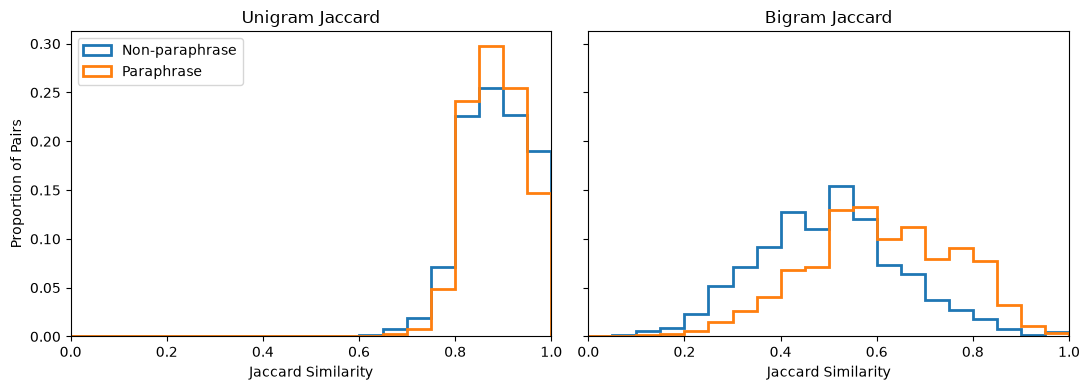

In [28]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4),
    sharey=True
)

measures = [
    ("unigram_jaccard", "Unigram Jaccard"),
    ("bigram_jaccard", "Bigram Jaccard")
]

for ax, (column, title) in zip(axes, measures):

    for label, name in [
        (0, "Non-paraphrase"),
        (1, "Paraphrase")
    ]:
        values = lexical_df.loc[
            lexical_df["label"] == label,
            column
        ]

        ax.hist(
            values,
            bins=np.linspace(0, 1, 21),
            weights=np.ones(len(values)) / len(values),
            histtype="step",
            linewidth=2,
            label=name
        )

    ax.set_title(title)
    ax.set_xlabel("Jaccard Similarity")
    ax.set_xlim(0, 1)

axes[0].set_ylabel("Proportion of Pairs")
axes[0].legend()

plt.tight_layout()
plt.show()

In [49]:

# Count instances of each class in train and validation
class_counts = pd.DataFrame({
    split: pd.Series(dataset[split]["label"]).value_counts()
    for split in ["train", "validation"]
}).T

# Ensure both classes are present and ordered
class_counts = class_counts.reindex(columns=[0, 1], fill_value=0)

class_counts.columns = ["Non-paraphrase (0)", "Paraphrase (1)"]

# Calculate totals and class proportions
class_counts["Total"] = class_counts[
    ["Non-paraphrase (0)", "Paraphrase (1)"]
].sum(axis=1)

class_counts["Paraphrase (%)"] = (
    100 * class_counts["Paraphrase (1)"] / class_counts["Total"]
).round(2)

display(class_counts)


,Non-paraphrase (0),Paraphrase (1),Total,Paraphrase (%)
train,27572,21829,49401,44.19
validation,4461,3539,8000,44.24


## 6. Vocabulary Characteristics

Vocabulary characteristics provide insight into the lexical diversity and frequency distribution of the dataset. In particular, the presence of rare or unseen words may affect the effectiveness of word-level representations.

This section examines vocabulary size, word frequencies, and out-of-vocabulary (OOV) rates to characterise the lexical properties of PAWS-Wiki before selecting a tokenisation strategy.

### 6.1. Vocabulary Size and Word Frequencies

We analyse the vocabulary of the training split by counting the total number of word occurrences, unique words, and hapax legomena (words appearing exactly once).

Both sentences from each training pair are considered, using the same basic tokenisation procedure as in the previous section.

In [40]:
# Count token occurrences across all training sentence pairs
word_counts = Counter()

for column in ["sentence1", "sentence2"]:
    for sentence in train_df[column]:
        word_counts.update(tokenize(sentence))

total_tokens = sum(word_counts.values())
vocab_size = len(word_counts)

# Words occurring exactly once in the entire corpus
hapax_count = sum(freq == 1 for freq in word_counts.values())

# Count in how many distinct training pairs each word occurs
pair_word_counts = Counter()

for s1, s2 in zip(train_df["sentence1"], train_df["sentence2"]):
    pair_words = set(tokenize(s1)) | set(tokenize(s2))
    pair_word_counts.update(pair_words)

# Words appearing in exactly one training pair
single_pair_words = sum(
    count == 1 for count in pair_word_counts.values()
)

vocab_summary = pd.DataFrame({
    "Statistic": [
        "Total token occurrences",
        "Vocabulary size",
        "Hapax legomena",
        "Hapax (% of vocabulary)",
        "Words appearing in one pair",
        "Single-pair words (% of vocabulary)"
    ],
    "Value": [
        total_tokens,
        vocab_size,
        hapax_count,
        round(100 * hapax_count / vocab_size, 2),
        single_pair_words,
        round(100 * single_pair_words / vocab_size, 2)
    ]
})

display(vocab_summary)

,Statistic,Value
0,Total token occurrences,2108372.00
1,Vocabulary size,31542.00
2,Hapax legomena,347.00
3,Hapax (% of vocabulary),1.10
4,Words appearing in one pair,637.00
5,Single-pair words (% of vocabulary),2.02


### 6.2. Out-of-Vocabulary Analysis

Out-of-vocabulary (OOV) words are tokens that appear in unseen data but are absent from the training vocabulary.

We measure both the proportion of unique OOV words (type rate) and the proportion of OOV word occurrences (token rate) in the validation split.

These statistics help assess the limitations of a word-level vocabulary when processing previously unseen text.

In [31]:
# Build vocabulary from training data
train_vocab = set(word_counts.keys())

# Tokenise validation sentences
val_tokens = []

for column in ["sentence1", "sentence2"]:
    for sentence in dataset["validation"][column]:
        val_tokens.extend(tokenize(sentence))

# Identify unseen words
val_vocab = set(val_tokens)
oov_words = val_vocab - train_vocab

# Calculate OOV rates
oov_type_rate = 100 * len(oov_words) / len(val_vocab)
oov_token_rate = 100 * sum(
    token not in train_vocab for token in val_tokens
) / len(val_tokens)

oov_summary = pd.DataFrame({
    "Statistic": [
        "Validation vocabulary size",
        "Unseen word types",
        "OOV type rate (%)",
        "OOV token rate (%)"
    ],
    "Value": [
        len(val_vocab),
        len(oov_words),
        round(oov_type_rate, 2),
        round(oov_token_rate, 2)
    ]
})

display(oov_summary)

,Statistic,Value
0,Validation vocabulary size,9169.00
1,Unseen word types,3159.00
2,OOV type rate (%),34.45
3,OOV token rate (%),8.80


## 7. Data Quality and Qualitative Inspection

Before developing the classification models, we examine the dataset for potential quality issues and dependencies between examples.

This analysis focuses on missing values, duplicated sentence pairs, and sentence overlap across dataset splits. We also inspect representative examples to better understand the linguistic phenomena involved in paraphrase detection.

### 7.1. Data Integrity and Duplicates

We examine the training split for missing values, empty sentences, duplicated pairs, and potential label inconsistencies.

Since paraphrase detection is symmetric, we also identify pairs appearing in reversed order and check whether identical unordered sentence pairs have conflicting labels. These analyses help assess data quality before designing the evaluation protocol.

In [43]:
# Check data integrity in the training split
quality_summary = pd.DataFrame({
    "Statistic": [
        "Missing sentence1",
        "Missing sentence2",
        "Missing labels",
        "Empty sentence1",
        "Empty sentence2",
        "Duplicate IDs"
    ],
    "Count": [
        train_df["sentence1"].isna().sum(),
        train_df["sentence2"].isna().sum(),
        train_df["label"].isna().sum(),
        train_df["sentence1"].fillna("").str.strip().eq("").sum(),
        train_df["sentence2"].fillna("").str.strip().eq("").sum(),
        train_df["id"].duplicated().sum()
    ]
})

display(quality_summary)

,Statistic,Count
0,Missing sentence1,0
1,Missing sentence2,0
2,Missing labels,0
3,Empty sentence1,0
4,Empty sentence2,0
5,Duplicate IDs,0


In [45]:

train_quality = train_df.copy()

# Ordered pairs: (A, B) differs from (B, A)
train_quality["ordered_pair"] = list(zip(
    train_quality["sentence1"],
    train_quality["sentence2"]
))

# Unordered pairs: (A, B) and (B, A) are equivalent
train_quality["unordered_pair"] = [
    tuple(sorted((s1, s2)))
    for s1, s2 in train_quality["ordered_pair"]
]

# Exact duplicates (same sentences in the same order)
exact_duplicates = train_quality["ordered_pair"].duplicated().sum()

# Duplicates regardless of sentence order
unordered_duplicates = train_quality["unordered_pair"].duplicated().sum()

# Pairs appearing in both orientations
unique_pairs = set(train_quality["ordered_pair"])

reversed_pairs = sum(
    s1 != s2 and (s2, s1) in unique_pairs
    for s1, s2 in unique_pairs
) // 2

# Unordered pairs with conflicting labels
conflicting_labels = (
    train_quality.groupby("unordered_pair")["label"]
    .nunique()
    .gt(1)
    .sum()
)

duplicate_summary = pd.DataFrame({
    "Statistic": [
        "Exact duplicate pairs (beyond first occurrence)",
        "Unordered duplicate pairs (beyond first occurrence)",
        "Distinct reversed pair combinations",
        "Unordered pairs with conflicting labels"
    ],
    "Count": [
        exact_duplicates,
        unordered_duplicates,
        reversed_pairs,
        conflicting_labels
    ]
})

display(duplicate_summary)


,Statistic,Count
0,Exact duplicate pairs (beyond first occurrence),52
1,Unordered duplicate pairs (beyond first occurrence),96
2,Distinct reversed pair combinations,44
3,Unordered pairs with conflicting labels,31


In [44]:
# Find unordered pairs with conflicting labels
conflicting_keys = (
    train_quality.groupby("unordered_pair")["label"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

# Inspect three conflicting pairs
examples = train_quality[
    train_quality["unordered_pair"].isin(conflicting_keys[:3])
]

with pd.option_context("display.max_colwidth", 160):
    display(
        examples[
            ["id", "sentence1", "sentence2", "label"]
        ].sort_values(["unordered_pair", "label"])
        if "unordered_pair" in
        ["id", "sentence1", "sentence2", "label"]
        else examples[
            ["id", "sentence1", "sentence2", "label"]
        ].sort_values("label")
    )

,id,sentence1,sentence2,label
21874,21875,Both Iran and Saudi Arabia opposed the use of force as a solution to regional problems and rejected the invasion of Kuwait by Iraq .,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",0
25588,25589,Announced to be created July 2013 .,July 2013 to be announced .,0
38932,38933,Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems and opposed the invasion of Kuwait by Iraq .,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",0
9869,9870,July 2013 to be announced .,Announced to be created July 2013 .,1
25041,25042,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",Both Iran and Saudi Arabia opposed the use of force as a solution to regional problems and rejected the invasion of Kuwait by Iraq .,1
26148,26149,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems and opposed the invasion of Kuwait by Iraq .,1


In [41]:
# Identify unordered sentence pairs with conflicting labels
label_counts = (
    train_quality
    .groupby("unordered_pair")["label"]
    .nunique()
)

conflicting_keys = label_counts[label_counts > 1].index

# Inspect a few conflicting pairs
selected_keys = conflicting_keys[:4]

conflicting_examples = train_quality[
    train_quality["unordered_pair"].isin(selected_keys)
].sort_values(
    ["sentence1", "sentence2", "label"]
)

with pd.option_context("display.max_colwidth", 160):
    display(conflicting_examples[
        ["id", "sentence1", "sentence2", "label"]
    ])

,id,sentence1,sentence2,label
25588,25589,Announced to be created July 2013 .,July 2013 to be announced .,0
21874,21875,Both Iran and Saudi Arabia opposed the use of force as a solution to regional problems and rejected the invasion of Kuwait by Iraq .,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",0
25041,25042,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",Both Iran and Saudi Arabia opposed the use of force as a solution to regional problems and rejected the invasion of Kuwait by Iraq .,1
26148,26149,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems and opposed the invasion of Kuwait by Iraq .,1
38932,38933,Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems and opposed the invasion of Kuwait by Iraq .,"Both Iran and Saudi Arabia rejected the use of force as a solution to regional problems , rejecting the invasion of Kuwait by Iraq .",0
34239,34240,By the middle of the 7th century alchemy was almost an entirely mystical discipline .,"By the middle of the 7th century , alchemy was an almost mystical discipline .",0
11819,11820,By the middle of the 7th century alchemy was almost an entirely mystical discipline .,"By the middle of the 7th century , alchemy was an almost mystical discipline .",1
9869,9870,July 2013 to be announced .,Announced to be created July 2013 .,1


### 7.2. Sentence Reuse and Split Overlap

Sentence pairs may share individual sentences even when the complete pairs are different. This can introduce dependencies between examples, particularly during cross-validation.

We first measure how frequently training sentences appear with multiple distinct partners. We then examine exact sentence overlap between the official training and validation splits.

The analysis helps assess potential dependencies in the evaluation protocol. The test split remains reserved for final evaluation.

In [46]:
from collections import defaultdict

# Record distinct partner sentences for each training sentence
sentence_partners = defaultdict(set)

for s1, s2 in zip(train_df["sentence1"], train_df["sentence2"]):
    sentence_partners[s1].add(s2)
    sentence_partners[s2].add(s1)

# Sentences appearing with multiple distinct partners
reused_sentences = {
    sentence
    for sentence, partners in sentence_partners.items()
    if len(partners) > 1
}

# Training pairs containing at least one reused sentence
affected_pairs = sum(
    s1 in reused_sentences or s2 in reused_sentences
    for s1, s2 in zip(train_df["sentence1"], train_df["sentence2"])
)

reuse_summary = pd.DataFrame({
    "Statistic": [
        "Unique training sentences",
        "Sentences with multiple distinct partners",
        "Training pairs containing a reused sentence",
        "Affected training pairs (%)"
    ],
    "Value": [
        len(sentence_partners),
        len(reused_sentences),
        affected_pairs,
        round(100 * affected_pairs / len(train_df), 2)
    ]
})

display(reuse_summary)

,Statistic,Value
0,Unique training sentences,40223.0
1,Sentences with multiple distinct partners,31018.0
2,Training pairs containing a reused sentence,49156.0
3,Affected training pairs (%),99.5


In [47]:
# Load the official validation split
val_df = dataset["validation"].to_pandas()

# Unique sentences in each split
train_sentences = (
    set(train_df["sentence1"])
    | set(train_df["sentence2"])
)

val_sentences = (
    set(val_df["sentence1"])
    | set(val_df["sentence2"])
)

# Identify exact sentence overlap
shared_sentences = train_sentences & val_sentences

# Validation pairs containing at least one training sentence
shared_pairs = sum(
    s1 in train_sentences or s2 in train_sentences
    for s1, s2 in zip(val_df["sentence1"], val_df["sentence2"])
)

# Identify repeated unordered pairs across splits
train_pairs = set(train_quality["unordered_pair"])

val_pairs = {
    tuple(sorted((s1, s2)))
    for s1, s2 in zip(val_df["sentence1"], val_df["sentence2"])
}

overlap_summary = pd.DataFrame({
    "Statistic": [
        "Shared unique sentences",
        "Validation pairs sharing a training sentence",
        "Affected validation pairs (%)",
        "Repeated unordered pairs"
    ],
    "Value": [
        len(shared_sentences),
        shared_pairs,
        round(100 * shared_pairs / len(val_df), 2),
        len(train_pairs & val_pairs)
    ]
})

display(overlap_summary)

,Statistic,Value
0,Shared unique sentences,0.0
1,Validation pairs sharing a training sentence,0.0
2,Affected validation pairs (%),0.0
3,Repeated unordered pairs,0.0


### 7.3. Qualitative Inspection

Finally, we inspect selected sentence pairs to better understand the linguistic challenges of PAWS-Wiki.

For each class, two randomly selected examples and two pairs with identical Bag-of-Words representations but different token order are examined.

This selection highlights both general sentence-pair characteristics and cases where lexical representations discard potentially relevant ordering information.

In [42]:
qualitative_examples = []

for label in [0, 1]:
    class_df = lexical_df[lexical_df["label"] == label]

    # Select two pairs with identical BoW but different order
    reordered = class_df[
        class_df["same_bow_diff_order"]
    ].sample(n=2, random_state=42)

    # Select two additional random examples
    random_examples = class_df.drop(
        reordered.index
    ).sample(n=2, random_state=42)

    selected = pd.concat([
        random_examples.assign(selection="Random"),
        reordered.assign(selection="Reordered BoW")
    ])

    qualitative_examples.append(selected)

qualitative_examples = pd.concat(qualitative_examples)

with pd.option_context("display.max_colwidth", 160):
    display(qualitative_examples[
        [
            "sentence1",
            "sentence2",
            "label",
            "unigram_jaccard",
            "bigram_jaccard",
            "selection"
        ]
    ])

,sentence1,sentence2,label,unigram_jaccard,bigram_jaccard,selection
14667,"Scatarie Island is an island in the Canadian province of Nova Scotia , located off the coast of Baleine , Cape Breton Island .","Cape Breton Island is an island located in the Canadian province of Nova Scotia , off the coast of Baleine , Scatarie Island .",0,1.000000,0.703704,Random
45446,The song was written by Thicke and Lamar alongside Dr. Luke and was produced by will.i.am and Cirkut .,The song was written together with will.i.am by Thicke and Lamar and produced by Dr. Luke and Cirkut .,0,0.823529,0.440000,Random
12163,"These canons were rejected later in 692 by the Eastern Council in Trullo , but approved by Pope Constantine .","These canons were approved later in 692 by the Eastern Council in Trullo , but rejected by Pope Constantine .",0,1.000000,0.652174,Reordered BoW
28508,"He began his studies in Budapest in 1946 at the Main Gimnázium , and from 1947 to 1951 he visited the Madách Gimnázium in Debrecen .","He began his studies at the Main Gimnázium in Debrecen in 1946 , and from 1947 to 1951 he visited the Madách Gimnázium in Budapest .",0,1.000000,0.689655,Reordered BoW
28665,A KWL chart can be used for all subjects in a whole group or small group atmosphere .,A KWL chart can be used for all subjects in a small group or in a whole group atmosphere .,1,1.000000,0.842105,Random
33658,"Another interpretation specifies Sicily separate from Naples , plus Jerusalem and Aragon .","Another interpretation specifies Sicily separated from Naples , plus Jerusalem and Aragon .",1,0.857143,0.714286,Random
5452,Jonathan Dakers met Edie Martyn as a child ( Beatrice Campbell ) .,As a child Jonathan Dakers met Edie Martyn ( Beatrice Campbell ) .,1,1.000000,0.714286,Reordered BoW
26853,"Scopa is white , but black at the front edge .","Scopa is white , at the front edge but black .",1,1.000000,0.538462,Reordered BoW


## 8. Preprocessing and Experimental Implications

### 8.1. Preprocessing Strategy

The exploratory analysis motivates a minimal preprocessing strategy aimed at preserving linguistic information relevant to paraphrase detection. Since PAWS-Wiki consists of sentence pairs with substantial lexical overlap, relatively small differences in word choice, ordering, or grammatical structure may determine whether two sentences convey the same meaning.

The following preprocessing decisions are adopted:

- **Case preservation:** Lowercasing is avoided to retain distinctions involving proper nouns, acronyms, and other case-sensitive expressions. Although this may increase vocabulary size, it prevents potentially informative differences from being discarded.
- **Stopword preservation:** Stopwords are retained because function words, including prepositions, pronouns, and negation markers, can affect semantic relationships between sentence components.
- **Punctuation preservation:** Punctuation is retained, as it may contribute to sentence interpretation. Tokenisation may separate punctuation marks from neighbouring words without removing them.
- **No stemming or lemmatisation:** Morphological normalisation is avoided to preserve grammatical and lexical distinctions that could be relevant to paraphrase detection.
- **Preservation of numbers and dates:** Numerical expressions and dates are not replaced by generic placeholders, since differences in these elements may change sentence meaning.
- **Minimal whitespace normalisation:** Leading, trailing, and redundant internal whitespace may be standardised without changing the lexical content or word order.

The training split exhibits a moderate class imbalance, with approximately 56% non-paraphrases and 44% paraphrases. Consequently, no class resampling is applied. Stratified evaluation and class-sensitive metrics will be considered to account for differences in class frequency.

Duplicated sentence pairs and potential label inconsistencies have also been identified. Rather than modifying the original dataset during exploratory analysis, these cases will be considered when constructing the cross-validation folds and interpreting the results.

### 8.2. Implications for Feature Extraction

The preprocessing strategy is intentionally conservative: information is preserved in the original sentences, while different feature representations determine which aspects of the text are accessible to each classifier.

In particular, unigram indicators and Bag-of-Words representations discard word-order information, even when the original text preserves it. Representations incorporating bigrams may capture local ordering patterns, while sequence-based models can process token order explicitly.

The tokenisation strategy will be implemented as part of the experimental pipeline. Word-level and subword approaches can be evaluated without applying irreversible transformations to the original sentences.

Any learned preprocessing components, including vocabularies, subword tokenisers, and feature-weighting statistics, will be fitted exclusively on the training portion of each cross-validation fold. The test split will remain untouched until the final evaluation.